# Data Reorganization & Balancing Pipeline

In this section, we automate the transformation of our 5-class dataset into a perfectly balanced **binary dataset** (Healthy vs. Sick). 

### Why build a Pipeline?
Instead of manually copying and modifying the original dataset, we use a Python script to create a new, clean environment (`Dataset_Knee_Osteoarthritis_Balenced`). This approach is better because:
1. **Safety**: We never alter or delete the original raw data.
2. **Automation**: By using a dynamic function, we apply the exact same mathematical logic to our `train`, `test`, and `val` folders without duplicating code, which prevents bugs.

### How does the balancing work?
To avoid model bias, the number of "Sick" images must equal the number of "Healthy" images. For each directory, the script will:
- **Step 1**: Count the exact number of "Healthy" images (Grade 0).
- **Step 2**: Calculate the total number of "Sick" images (sum of Grades 1, 2, 3, and 4).
- **Step 3**: Calculate a **retention ratio** (`Total Healthy / Total Sick`).
- **Step 4**: Copy 100% of the "Healthy" images to a new `healthy` folder.
- **Step 5**: Randomly sample images from the "Sick" grades using the calculated ratio, and copy them to a new `sick` folder. 

*Note: During Step 5, we rename the sick images to include their original grade (e.g., `grade2_image.jpg`). This ensures we don't accidentally overwrite files that share the same name across different folders.*

In [11]:
import os
import shutil
import random

def balance_and_transfer(source_dir, final_dir):
    # Delete the folder if it exists to start from scratch.
    if os.path.exists(final_dir):
        shutil.rmtree(final_dir)

    #1. Creating destination directories
    os.makedirs(os.path.join(final_dir, "healthy"), exist_ok=True)
    os.makedirs(os.path.join(final_dir, "sick"), exist_ok=True)
    
    #2. Calculating the ratio
    healthy_files = os.listdir(os.path.join(source_dir, "0"))
    total_healthy = len(healthy_files)
    
    sick_grades = ["1", "2", "3", "4"]
    total_sick_initial = 0
    for g in sick_grades:
        total_sick_initial += len(os.listdir(os.path.join(source_dir, g)))
        
    ratio = total_healthy / total_sick_initial
    print(f"- Case retention ratio: {ratio*100:.2f}%")
    
    #3. Transfer of Healthy Cases (Grade 0)
    print("- Copy of healthy images...")
    for filename in healthy_files:
        src = os.path.join(source_dir, "0", filename)
        dst = os.path.join(final_dir, "healthy", filename)
        shutil.copy(src, dst)
        
    #4. Transfer of Sick Cases (Grades 1 to 4)
    print("- Copy and balance of diseased images...")
    for g in sick_grades:
        current_grade_path = os.path.join(source_dir, g)
        all_imgs = os.listdir(current_grade_path)
        
        num_to_keep = int(len(all_imgs) * ratio)
        imgs_to_copy = random.sample(all_imgs, num_to_keep)
        
        for filename in imgs_to_copy:
            src = os.path.join(current_grade_path, filename)
            dst = os.path.join(final_dir, "sick", f"grade{g}_{filename}")
            shutil.copy(src, dst)
            
    # 5. Transfer Summary
    final_healthy_count = len(os.listdir(os.path.join(final_dir, 'healthy')))
    final_sick_count = len(os.listdir(os.path.join(final_dir, 'sick')))
    print(f"-> Success ! Healthy: {final_healthy_count} | Sick: {final_sick_count}\n")

base_source = "../Dataset_Knee_Osteoarthritis"
base_final = "../Dataset_Knee_Osteoarthritis_Balanced"

repertoires = ["train", "test", "val"]

for rep in repertoires:
    src_path = os.path.join(base_source, rep)
    dst_path = os.path.join(base_final, rep)

    balance_and_transfer(src_path, dst_path)

print("The entire database has been successfully reorganized and balanced!")


- Case retention ratio: 65.46%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 2286 | Sick: 2284

- Case retention ratio: 62.83%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 639 | Sick: 637

- Case retention ratio: 65.86%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 328 | Sick: 325

The entire database has been successfully reorganized and balanced!


# Knee Osteoarthritis Dataset with Severity Grading from Dataset Exploration

This Notebook explores a dataset of knee X-rays used to detect osteoarthritis levels (Grade 0 to 4). To optimize CVRIE's learning, we will transform this multi-class problem into a binary classification:

- Healthy (Class 0): Grade 0 images.
-  Sick (Class 1): Combination of Grades 1, 2, 3, and 4.

Dataset structure
- train/
- val/
- test/

Classes or Labels
- healthy
- sick

Goals:
-  Analyze the distribution: Count images in each of the 5 original grades.
-  Data Balancing: Implement a proportional reduction of "Sick" cases to match the number of "Healthy" cases. This prevents the model from being biased toward the majority class.
- Visualization: Display samples of the different grades to understand the progression of the disease.

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

## Dataset Dir and Labels

In [13]:
train_dir = "../Dataset_Knee_Osteoarthritis_Balanced/train"
val_dir = "../Dataset_Knee_Osteoarthritis_Balanced/val"
test_dir = "../Dataset_Knee_Osteoarthritis_Balanced/test"

print("Labels found in Train:", os.listdir(train_dir))


Labels found in Train: ['sick', 'healthy']


## Nbr of images per classes for each dir

In [14]:
def count_images_in_dir(base_dir):
    total = 0
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        total += len(os.listdir(path))
    return total

print("Total Train images:", count_images_in_dir(train_dir))
print("Total Validation images:", count_images_in_dir(val_dir))
print("Total Test images:", count_images_in_dir(test_dir))


Total Train images: 4570
Total Validation images: 653
Total Test images: 1276


## Dataset size analysis

The count_images function reveal that the validations folder has 653 images, which is significantly smaller than the train set and test set.
This may limit the reliability of validation metrics during model training.

### Class Balance Verification

In [15]:
def count_per_class(base_dir):
    counts = {}
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        counts[label] = len(os.listdir(path))
    return counts

train_balance = count_per_class(train_dir)
test_balance = count_per_class(test_dir)
val_balance = count_per_class(val_dir)

print("Train balance:", train_balance)
print("Test balance:", test_balance)
print("Validation balance:", val_balance)


Train balance: {'sick': 2284, 'healthy': 2286}
Test balance: {'sick': 637, 'healthy': 639}
Validation balance: {'sick': 325, 'healthy': 328}


### Visualization of the imbalanced

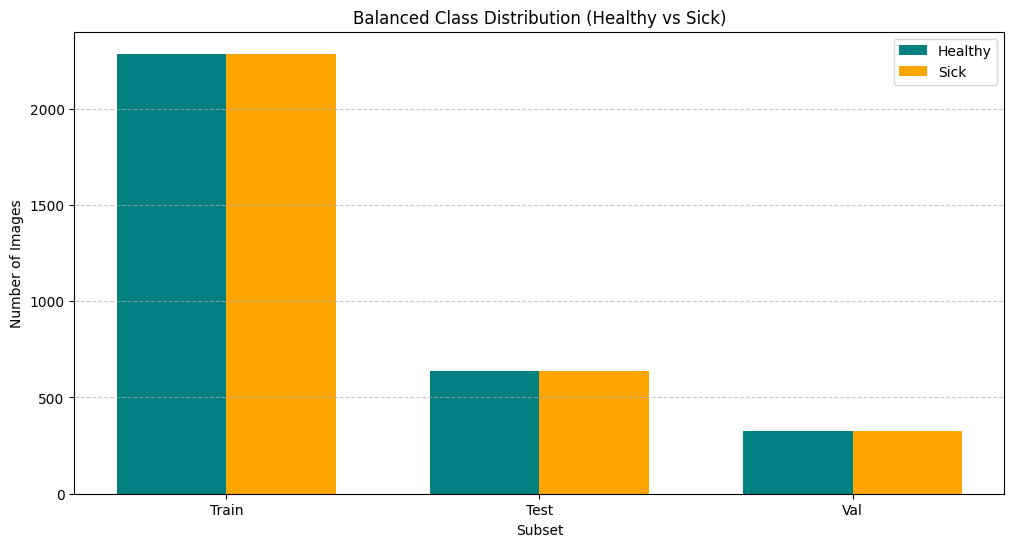

In [16]:
def plot_distribution():
    labels = ["Train", "Test", "Val"]
    healthy_counts = [train_balance["healthy"], test_balance["healthy"], val_balance["healthy"]]
    sick_counts = [train_balance["sick"], test_balance["sick"], val_balance["sick"]]

    x = np.arange(len(labels))
    width = 0.35
    plt.figure(figsize=(12, 6))

    plt.bar(x - width/2, healthy_counts, width, label="Healthy", color="teal")
    plt.bar(x + width/2, sick_counts, width, label="Sick", color="orange")

    plt.xlabel("Subset")
    plt.ylabel("Number of Images")
    plt.title("Balanced Class Distribution (Healthy vs Sick)")
    plt.xticks(x, labels)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

plot_distribution()


### Conclusion
The graph confirms a perfectly balanced distribution between the classes for each segment of the dataset, which eliminates any initial bias and guarantees rigorous learning based on the real characteristics of the images.


## Class Distribution Analysis

The distribution is now perfectly balanced (1:1 ratio). By reducing the majority class (Sick) using a proportional undersampling strategy, we have eliminated the risk of model bias. The model will now learn to identify both classes with equal importance.

### Visualizing Samples

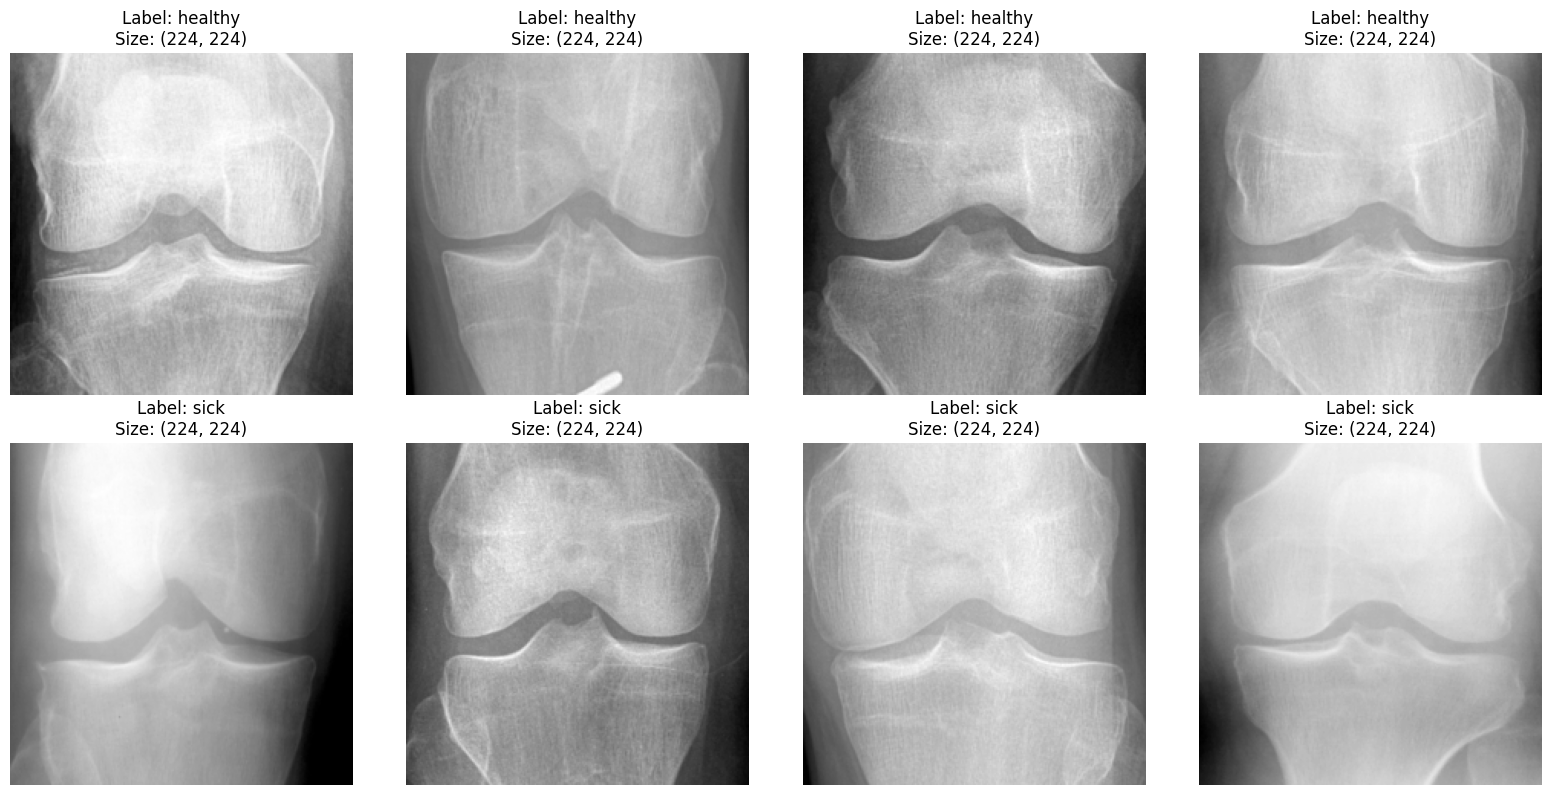

In [17]:
def display_random_samples(base_dir, labels=['healthy', 'sick'], n=4):
    plt.figure(figsize=(16, 8))
    for i, category in enumerate(labels):
        folder_path = os.path.join(base_dir, category)
        img_names = random.sample(os.listdir(folder_path), n)
        
        for j, img_name in enumerate(img_names):
            plt.subplot(len(labels), n, i * n + j + 1)
            img_path = os.path.join(folder_path, img_name)
            img = Image.open(img_path)
            
            plt.imshow(img, cmap='gray')
            plt.title(f"Label: {category}\nSize: {img.size}")
            plt.axis('off')
            
    plt.tight_layout()
    plt.show()

display_random_samples(train_dir)


# PRE-PROCESSING OF Knee osteoarthritis DATASET

During the eda, we notice two problems:
- Img do not have the same sizes
- The test folder is umbalanced and do not have enough img

In [18]:
import os
import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder

### Transform each img and their label into numpy arrays for model training

In [19]:
pro_train_dir = "../Dataset_Knee_Osteoarthritis_Balanced/train"
pro_val_dir = "../Dataset_Knee_Osteoarthritis_Balanced/val"
pro_test_dir = "../Dataset_Knee_Osteoarthritis_Balanced/test"

def transform_img(folder):
    images = []
    labels = []
    for label in os.listdir(folder):
        label_path = os.path.join(folder, label)
        for file in os.listdir(label_path):
            file_path = os.path.join(label_path, file)
            img = Image.open(file_path)
            img_array = np.array(img)
            images.append(img_array)
            labels.append(label)
    return np.array(images), np.array(labels)

### Affect features (img) and labels (HEALTHY or SICK)

In [20]:
X_train, y_train = transform_img(pro_train_dir)
X_val, y_val = transform_img(pro_val_dir)
X_test, y_test = transform_img(pro_test_dir)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4570, 224, 224)
(653, 224, 224)
(1276, 224, 224)


### Shuffle values

In [21]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state=42)
X_val, y_val = shuffle(X_val, y_val, random_state=42)
X_test, y_test = shuffle(X_test, y_test, random_state=42)

### Reshape features to only have one pixels

In [22]:
h, w = X_train.shape[1], X_train.shape[2]

X_train = X_train.reshape(len(X_train), h * w)
X_val = X_val.reshape(len(X_val), h * w)
X_test = X_test.reshape(len(X_test), h * w)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4570, 50176)
(653, 50176)
(1276, 50176)


### Encode the labels to  affect digits to each labels

In [23]:
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_val = encoder.transform(y_val)
y_test = encoder.transform(y_test)

print("y_train:", y_train)
print("y_val:", y_val)
print("y_test:", y_test)

y_train: [1 1 1 ... 0 0 1]
y_val: [1 1 1 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 0 0 0 0 1 1 1 0 1 1 1 1 0 1 1 0 1 1
 0 0 0 0 1 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 0 1 1 1 1 0 0 0 1 0 1 1 0
 1 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 1 0 0 0 1 1 0 1 1 1 0 0 1 1 1 1 1 1 0 1 0
 1 1 0 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 0 1
 0 1 1 0 1 1 1 0 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1
 0 1 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 1 0 1 1 0 1 0 1 0 1 1 0 1
 1 1 1 0 1 0 1 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0 1 0 1
 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 1 1 0 1 1
 0 1 1 0 1 0 0 1 1 0 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1 0 0 0 1 1 1 0 0 0
 0 1 1 0 0 0 1 1 0 0 1 0 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 0 0 1
 0 1 0 1 1 1 0 0 0 1 0 0 1 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 1 0 0
 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 1 1 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 1
 1 0 0 1 0 1 1 1 1 0 1 1 1 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 1 0

# Model Training: Machine Learning Approach

Now that our image data is pre-processed and flattened into 1D vectors, we can proceed to the training phase. We will train and compare three classic Machine Learning algorithms to see which one performs best on our data:
1. Support Vector Machine (SVM)
2. Random Forest Classifier
3. Logistic Regression (The classification equivalent of linear regression)

### Data Normalization
Before training, we need to scale the pixel values to a range between 0 and 1. This helps the algorithms process the data faster and more accurately.

In [24]:
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Data normalized! Max value:", X_train.max())
# En faisant $X / 255.0$ 
# Cela permet au modèle de faire ses calculs mathématiques beaucoup plus 
# vite et avec plus de précision.

Data normalized! Max value: 1.0


### Support Vector Machine (SVM)
First, we will train the SVM model. It is a reliable algorithm for binary classification tasks.

In [25]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Initialize and train the SVM model
svm_model = SVC(random_state=42)
print("Training SVM...")
svm_model.fit(X_train, y_train)
print("SVM training completed.")

# Predict on the test set
y_pred_svm = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, y_pred_svm)
print(f"Accuracy Random Forest : {svm_accuracy * 100:.2f}%")


Training SVM...
SVM training completed.
Accuracy Random Forest : 63.24%


Let's evaluate the SVM performance using a confusion matrix to see exactly where the model makes mistakes.

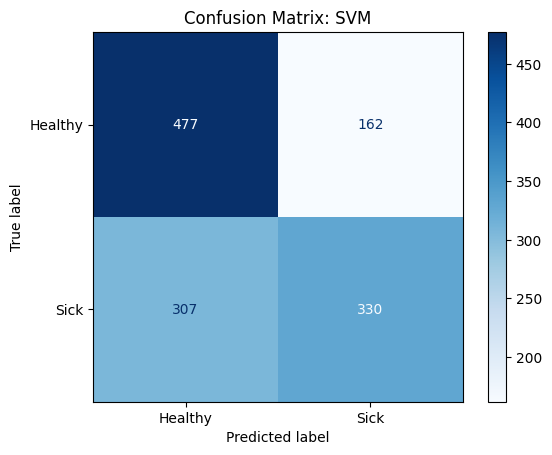

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report

# Generate and plot confusion matrix for SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=["Healthy", "Sick"])

disp_svm.plot(cmap='Blues')
plt.title("Confusion Matrix: SVM")
plt.show()

# print("Accuracy SVM:", accuracy_score(y_test, y_pred_svm))
# print(classification_report(y_test, y_pred_svm, target_names=["Healthy", "Sick"]))

**SVM Conclusion:**
The matrix shows that the SVM model achieves a baseline accuracy of around 64%. However, it struggles to correctly identify the "Sick" patients, producing many false negatives. In a medical context, missing a sick patient is a critical error.

### Random Forest Classifier
Next, we will train a Random Forest model. This algorithm builds multiple decision trees and merges them together to get a more accurate and stable prediction.

In [27]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(random_state=42)
print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Random Forest training completed.")

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Accuracy score
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy Random Forest : {rf_accuracy * 100:.2f}%")


Training Random Forest...
Random Forest training completed.
Accuracy Random Forest : 62.46%


Let's look at the confusion matrix for the Random Forest model to see if it performs better than the SVM.

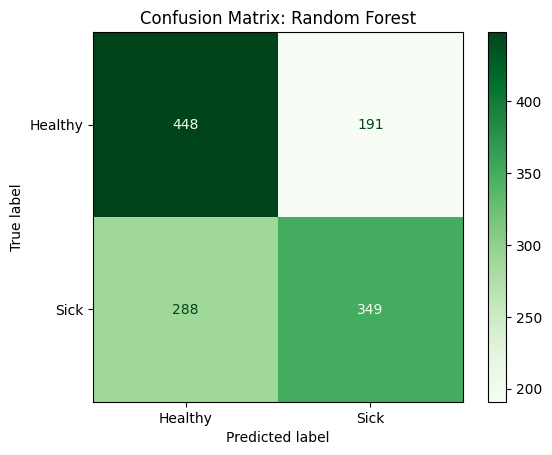

In [28]:
# Generate and plot confusion matrix for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Healthy", "Sick"])

disp_rf.plot(cmap='Greens')
plt.title("Confusion Matrix: Random Forest")
plt.show()

# print("Accuracy Random Forest:", accuracy_score(y_test, y_pred_rf))
# print(classification_report(y_test, y_pred_rf, target_names=["Healthy", "Sick"]))

**Random Forest Conclusion:**
The matrix indicates the performance of the Random Forest. We observe how the true positives and false negatives have shifted compared to the SVM.

### Logistic Regression
Finally, we train a Logistic Regression model. It is a fundamental linear algorithm used for binary classification that estimates the probability of an image belonging to the "Sick" or "Healthy" class.

In [29]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42, max_iter=3000, solver='saga')
print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)
print("Logistic Regression training completed.")

y_pred_lr = lr_model.predict(X_test)

# Accuracy score
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy Random Forest : {lr_accuracy * 100:.2f}%")


Training Logistic Regression...
Logistic Regression training completed.
Accuracy Random Forest : 65.05%


/home/harry-hounsou/Ridwane777/semester4/medical-vision-ml/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Let us generate the confusion matrix for the Logistic Regression model to complete our baseline comparisons.

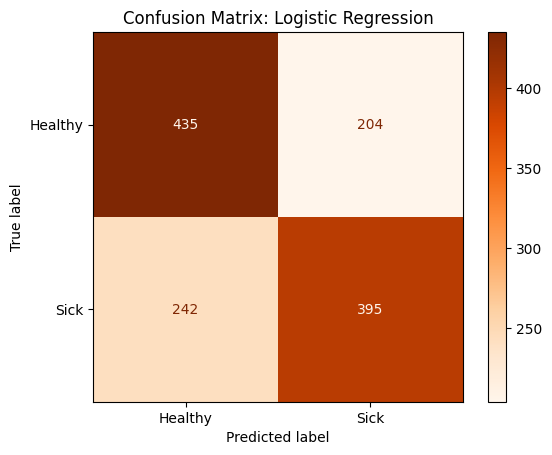

In [30]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Healthy", "Sick"])
disp_lr.plot(cmap='Oranges')
plt.title("Confusion Matrix: Logistic Regression")
plt.show()

# print("Accuracy Logistic Regression:", accuracy_score(y_test, y_pred_lr))

**Logistic Regression Conclusion:**

The Logistic Regression model serves as a fundamental linear classifier for this dataset. By analyzing its confusion matrix, we can observe how a linear approach handles the high-dimensional flattened pixel data. While it provides a clear baseline for binary classification (Healthy vs. Sick), its performance is often limited by the linear nature of its decision boundary when dealing with complex medical images.

**Base Models Comparison:**

We have now evaluated three distinct algorithms—SVM, Random Forest, and Logistic Regression—using their default configurations. This comparison allows us to identify which mathematical approach is naturally most effective for detecting knee osteoarthritis before any fine-tuning. However, these initial results only represent the "out-of-the-box" performance. Since default parameters are rarely optimal for medical-grade diagnostics, we will now proceed to hyperparameter optimization to maximize our accuracy and recall.